# Maintainability Triage — Experimental Evaluation and Results
**Project:** J26-SE-361 · **Research component:** Code Cleanliness & Maintainability

This notebook presents reproducible results from the existing research evidence. It is not a substitute for independent ground truth and does not introduce fabricated labels or model ratings. Run from `Code Cleanliness/evaluation/notebooks/Maintainability_Triage_Evaluation.ipynb` within the project workspace. All charts use recorded measurements; unavailable evidence is identified explicitly.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Use the notebook location if set; alternatively locate the project from the working directory.
candidates = [Path.cwd(), *Path.cwd().parents]
eval_root = next((p / 'Code Cleanliness' / 'evaluation' for p in candidates if (p / 'Code Cleanliness' / 'evaluation').is_dir()), None)
if eval_root is None:
    eval_root = next((p for p in candidates if p.name == 'evaluation' and (p / 'results').is_dir()), None)
if eval_root is None:
    raise FileNotFoundError('Open J26-SE-361 as the VS Code workspace and set the notebook kernel working directory to the project root or evaluation directory.')
base = eval_root / 'results' / 'final_evaluation'
completion = eval_root / 'final_completion'
print('Evaluation root:',eval_root)
print('Existing final results:',base.exists())

def csv_or_none(path):
    if not path.is_file():
        print('MISSING:',path.relative_to(eval_root) if path.is_relative_to(eval_root) else path)
        return None
    return pd.read_csv(path)


Evaluation root: c:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation
Existing final results: True


## 1. Implementation evidence
Repository-wide Java parsing and cross-file analysis; 12 maintainability concerns; grouping and lexicographic priority ranking; VS Code extension + separate Qwen inference. These are implementation features, not empirical accuracy claims.

**Recorded Maven outcome:** 156 tests run, 0 failures, 0 errors, 0 skipped (last user-verified run). **VS Code demonstration:** 5 Java files parsed, 6 findings, 2 issue groups, 0 parse failures, and a Qwen explanation returned.

Integration screenshots: 6


**VSCode_Integration_0.png**

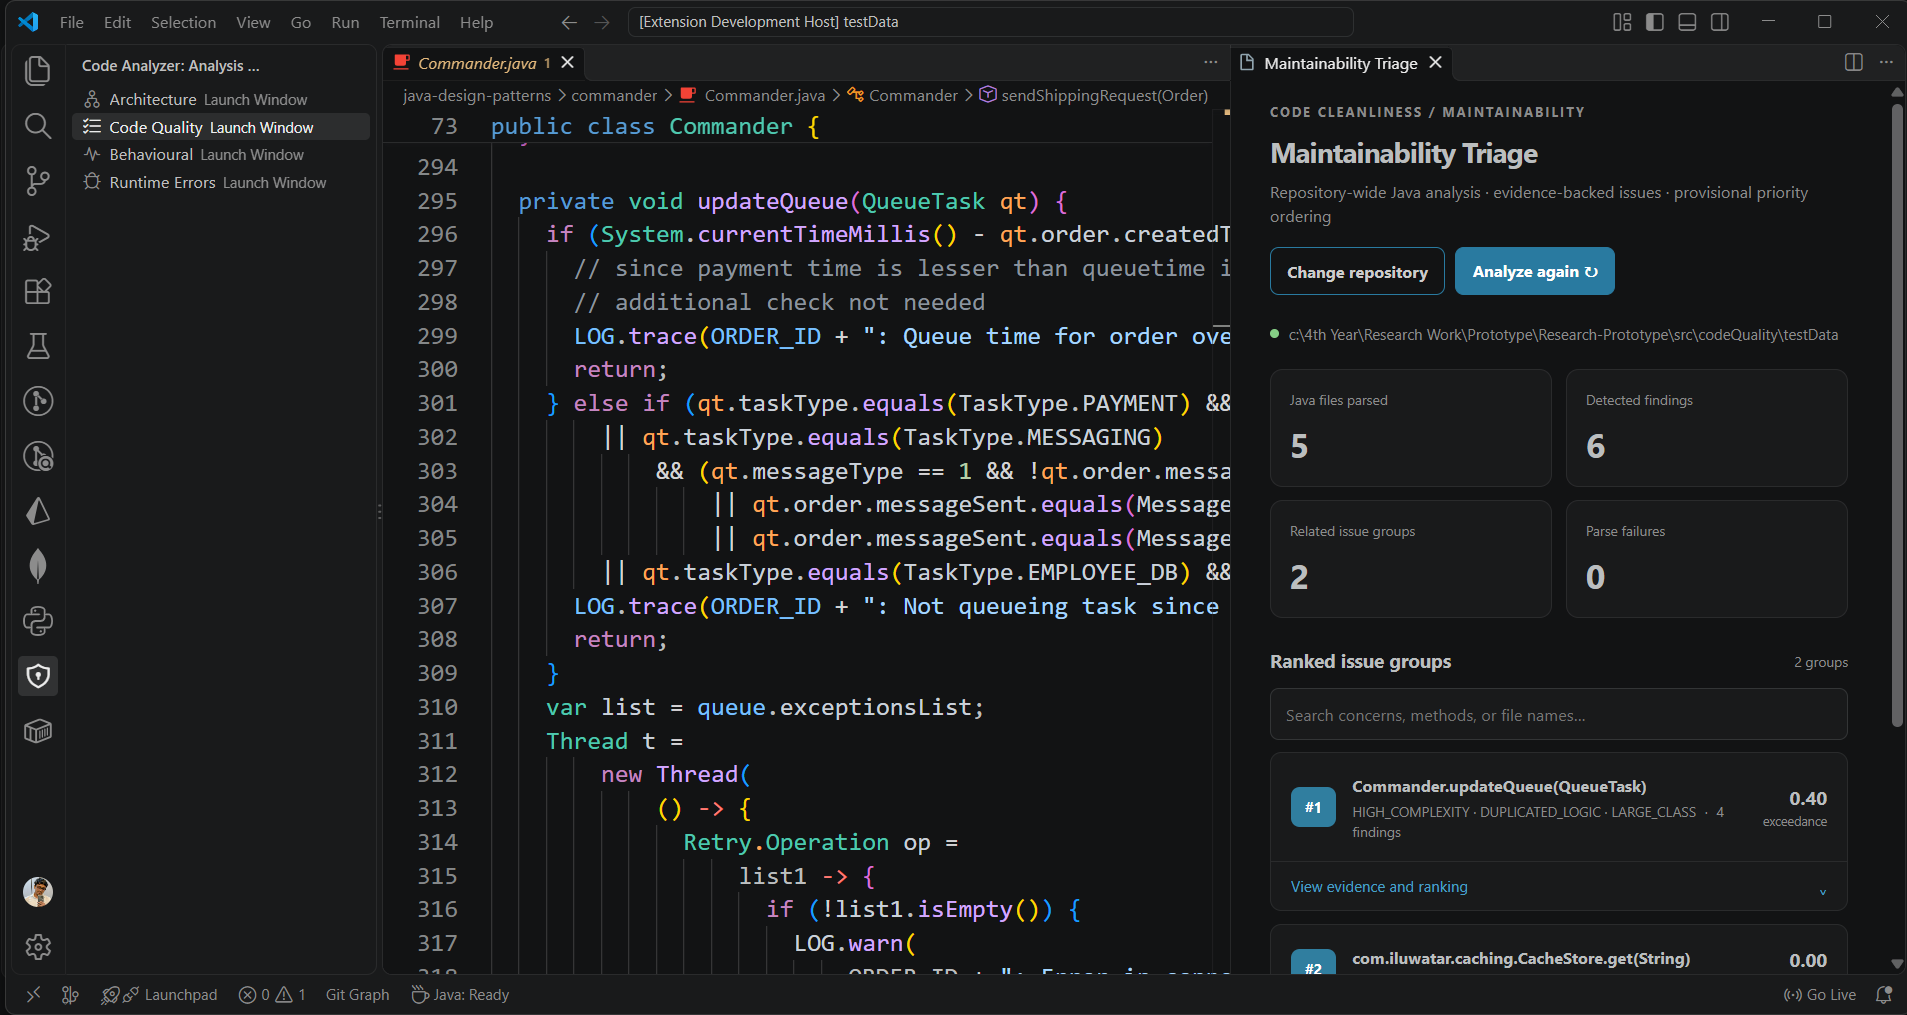

**VSCode_Integration_1.png**

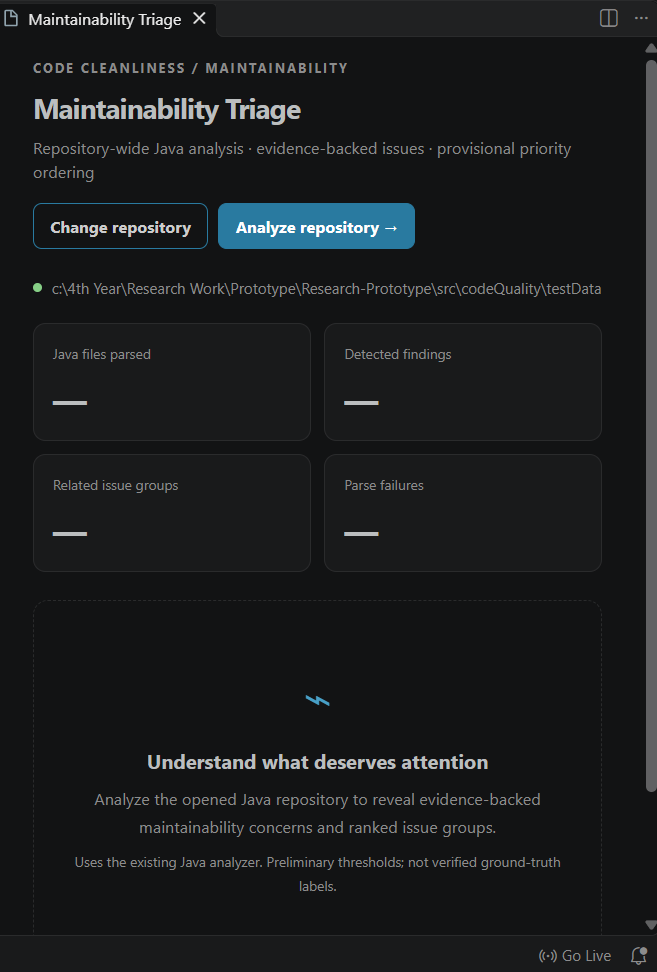

**VSCode_Integration_2.png**

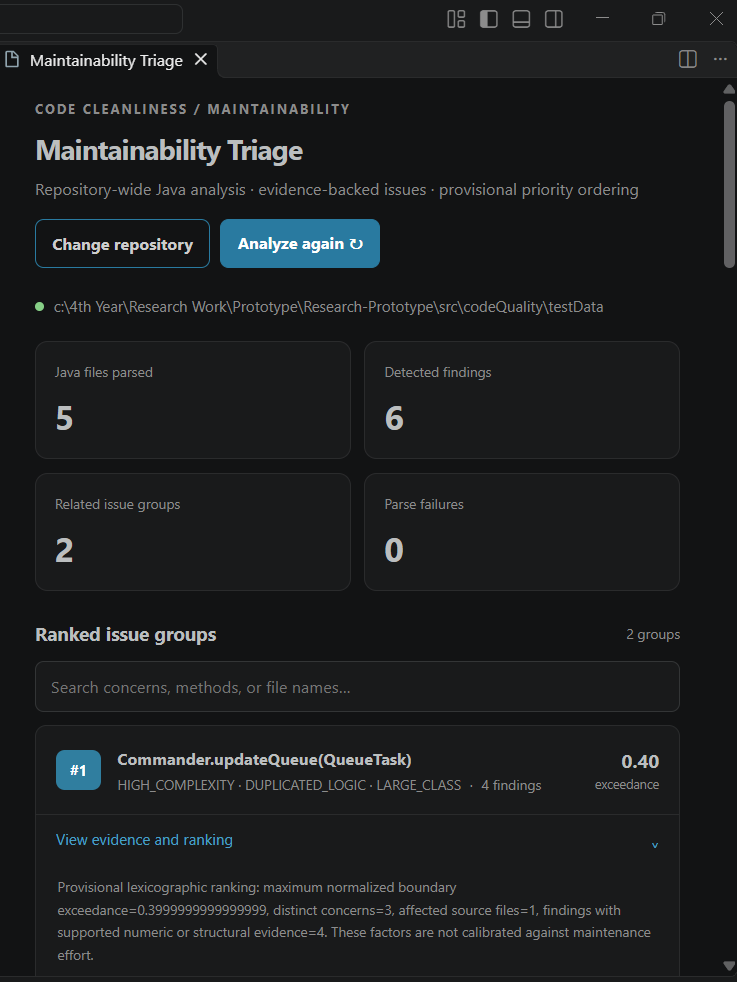

In [2]:
screens = completion / 'integration_screenshots'
shots = sorted(screens.glob('*.png')) if screens.is_dir() else []
print('Integration screenshots:',len(shots))
for shot in shots[:3]:
    display(Markdown('**'+shot.name+'**'))
    display(Image(filename=str(shot), width=760))

## 2. External detection benchmark — MLCQ and PMD
Below are **recorded sample-level confusion counts**. They refer to **36 scored observations per concern**, not the full MLCQ dataset. Precision is undefined when no positive predictions are made. The PMD comparison uses proxy rules; the concern definitions are not necessarily identical.

,Concern,Method,TP,FP,FN,TN,Precision,Recall,F1
0,Long Method,Analyzer,8,0,9,19,1.0,0.471,0.640
1,Long Method,PMD proxy,2,0,15,19,1.0,0.118,0.211
2,Blob / God Class,Analyzer,0,0,17,19,NaN,0.000,0.000
3,Blob / God Class,PMD proxy,9,0,8,19,1.0,0.529,0.692


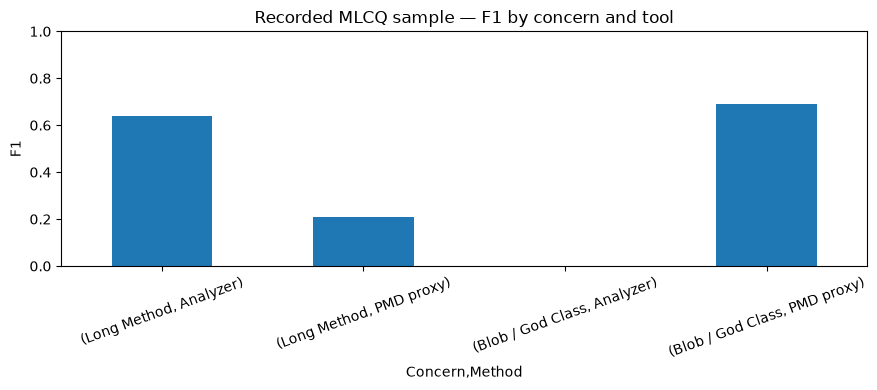

In [3]:
counts = pd.DataFrame([
 {'Concern':'Long Method','Method':'Analyzer','TP':8,'FP':0,'FN':9,'TN':19},
 {'Concern':'Long Method','Method':'PMD proxy','TP':2,'FP':0,'FN':15,'TN':19},
 {'Concern':'Blob / God Class','Method':'Analyzer','TP':0,'FP':0,'FN':17,'TN':19},
 {'Concern':'Blob / God Class','Method':'PMD proxy','TP':9,'FP':0,'FN':8,'TN':19},
])
counts['Precision'] = counts.apply(lambda x: x.TP/(x.TP+x.FP) if x.TP+x.FP else float('nan'),axis=1)
counts['Recall'] = counts.apply(lambda x: x.TP/(x.TP+x.FN) if x.TP+x.FN else float('nan'),axis=1)
counts['F1'] = counts.apply(lambda x: 2*x.TP/(2*x.TP+x.FP+x.FN) if 2*x.TP+x.FP+x.FN else 0.0,axis=1)
display(counts.round(3))
ax=counts.set_index(['Concern','Method'])['F1'].plot.bar(figsize=(9,4),rot=20)
ax.set_ylim(0,1);ax.set_ylabel('F1');ax.set_title('Recorded MLCQ sample — F1 by concern and tool');plt.tight_layout();plt.show()


**Interpretation:** Analyzer Long Method F1 is ≈0.64, while Blob/God Class is 0.00 on the evaluated sample. This result does **not** establish overall superiority over PMD. These sample-level figures should be reconciled against original scoring sheets before further publication.

## 3. Grouping diagnostic
The 15-pair source-based pilot contains analyzer grouping decisions. A preliminary AI-assisted diagnostic exists, but **independent reference labels are missing**. Thus independent grouping precision/recall/F1 **cannot be computed**.

Pilot pair count: 15


,Same group?,Pairs
0,0,8
1,1,7


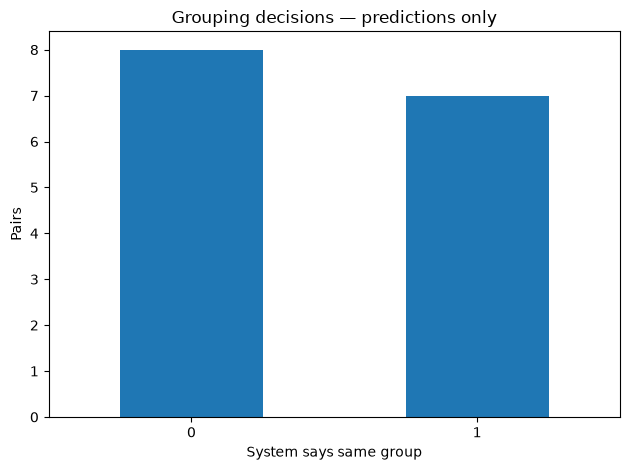

In [4]:
pairs = csv_or_none(base/'grouping'/'pilot_pairwise_review.csv')
if pairs is not None:
    print('Pilot pair count:',len(pairs))
    if 'system_same_group' in pairs:
        display(pairs['system_same_group'].value_counts(dropna=False).rename_axis('Same group?').reset_index(name='Pairs'))
        pairs['system_same_group'].value_counts(dropna=False).plot.bar(title='Grouping decisions — predictions only',rot=0)
        plt.xlabel('System says same group');plt.ylabel('Pairs');plt.tight_layout();plt.show()


## 4. Priority ranking — saturation audit
The implemented ranker uses lexicographic ordering: maximum normalized boundary exceedance → number of concerns → affected files → supported findings → stable group ID. The exceedance factor clamps to [0, 1]. These 40 groups were **selected from high ranks**, so the sample is biased and cannot establish independent ordering correctness.

Groups: 40  | valid scores: 40  | saturated at 1.0: 40
Available independent ranks: 0


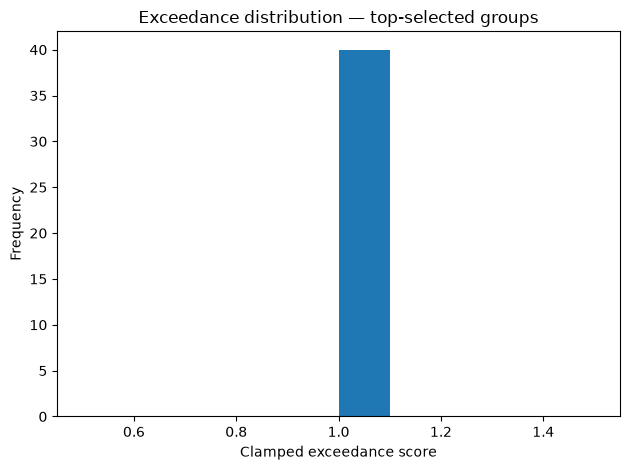

In [5]:
ranking=csv_or_none(base/'ranking'/'ranking_independent_review.csv')
if ranking is not None:
    s=pd.to_numeric(ranking.get('exceedance_score'),errors='coerce')
    print('Groups:',len(ranking),' | valid scores:',s.notna().sum(),' | saturated at 1.0:',s.eq(1.0).sum())
    print('Available independent ranks:',pd.to_numeric(ranking.get('independent_priority_rank'),errors='coerce').notna().sum() if 'independent_priority_rank' in ranking else 0)
    s.plot.hist(bins=10,title='Exceedance distribution — top-selected groups')
    plt.xlabel('Clamped exceedance score');plt.tight_layout();plt.show()


**Controlled verification:** The seven existing ranking tests plus four regression tests passed as part of the 156-test suite. Those tests verify the implemented ordering rules, **not correlation with actual maintenance priorities**.

## 5. Qwen2.5-Coder-7B-Instruct — Base vs LoRA
Six controlled recorded responses (three cases × two models) provide descriptive latency and response-length comparisons, not generalizable accuracy or model superiority. Numerical references absent from provided evidence are **screening flags only**, not verified hallucinations.

,responses,mean_seconds,mean_words
model,,,
base,3,11.140,124.000
fine_tuned,3,12.863,115.333


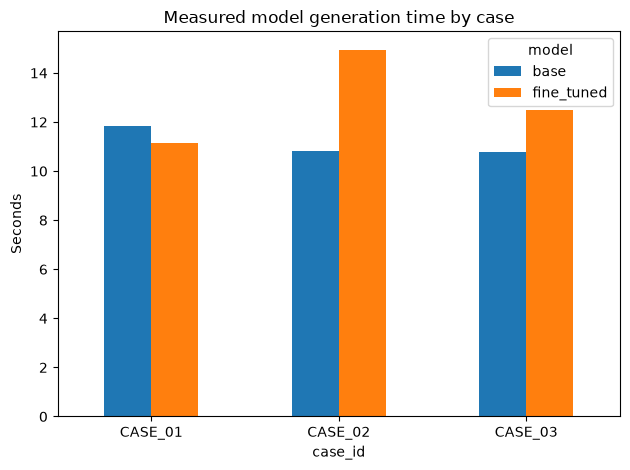

,case_id,model,generation_seconds,evidence_numbers,response_only_numbers,response_only_number_count
0,CASE_01,base,11.820,NaN,"13, 14",2
1,CASE_01,fine_tuned,11.134,NaN,14,1
2,CASE_02,base,10.811,NaN,NaN,0
3,CASE_02,fine_tuned,14.949,NaN,NaN,0
4,CASE_03,base,10.789,NaN,2000,1
5,CASE_03,fine_tuned,12.505,NaN,NaN,0


In [6]:
llm=csv_or_none(base/'llm'/'base_vs_finetuned_review.csv')
if llm is not None:
    llm['generation_seconds']=pd.to_numeric(llm['generation_seconds'],errors='coerce')
    llm['response_words']=llm['response'].fillna('').astype(str).str.split().str.len()
    display(llm.groupby('model').agg(responses=('case_id','count'),mean_seconds=('generation_seconds','mean'),mean_words=('response_words','mean')).round(3))
    pivot=llm.pivot_table(index='case_id',columns='model',values='generation_seconds')
    pivot.plot.bar(title='Measured model generation time by case',ylabel='Seconds',rot=0)
    plt.tight_layout();plt.show()
    flags=csv_or_none(base/'llm'/'qwen_numeric_grounding_screen.csv')
    if flags is not None: display(flags.head(10))


## 6. Repository scalability — recorded single-run experiment
These measurements were collected using copied Apache Commons Lang Java sources with a **flattened dependency structure**. They are **not a 1000-file measurement** and cannot establish average runtime or worst-case guarantees. Large increase at 500 files is an observed performance concern.

,selected_files,elapsed_seconds,exit_code,json_exists,method
0,100,19.387,0,True,single_run_copied_java_sources_flattened_depen...
1,250,26.094,0,True,single_run_copied_java_sources_flattened_depen...
2,500,613.553,0,True,single_run_copied_java_sources_flattened_depen...


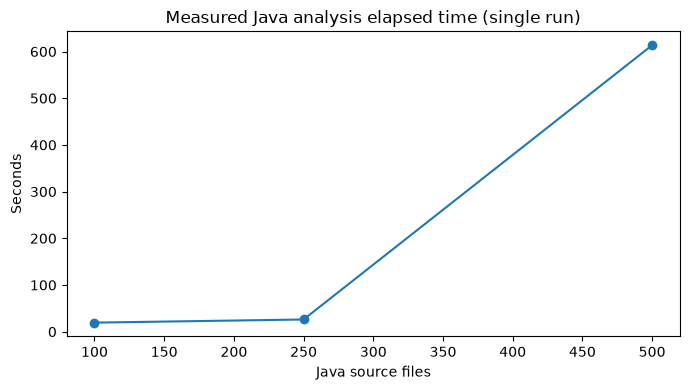

In [7]:
bench=csv_or_none(completion/'benchmark_results'/'benchmark_measurements.csv')
if bench is not None:
    display(bench.drop(columns=['source_repository'],errors='ignore'))
    for name in ('selected_files','elapsed_seconds'):
        bench[name]=pd.to_numeric(bench[name],errors='coerce')
    x=bench.dropna(subset=['selected_files','elapsed_seconds']).sort_values('selected_files')
    ax=x.plot.line(x='selected_files',y='elapsed_seconds',marker='o',legend=False,figsize=(7,4))
    ax.set_title('Measured Java analysis elapsed time (single run)');ax.set_xlabel('Java source files');ax.set_ylabel('Seconds');plt.tight_layout();plt.show()


**Measured:** 100 files → 19.387 s; 250 files → 26.094 s; 500 files → 613.553 s. At 500 files, analyzer log recorded 500 parsed / 0 failed, 4,160 findings and 1,250 groups. Runtime and file-count data are measurements, not detection ground truth.

## 7. Research conclusions and validation boundaries

**Implemented and verified:** repository-level Java analysis; maintainability detection; issue grouping and provisional lexicographic priority ranking; functional VS Code integration with separate Qwen inference; 156 passing Java tests.

**Empirical evidence available:** selected MLCQ/PMD comparisons; grouping and ranking diagnostics; Qwen controlled outputs; measured 100–500-file scalability experiments.

**Not independently established:** grouping precision/recall/F1 on representative independent annotations; agreement of priority ranking with actual maintenance priorities; superiority of fine-tuned Qwen explanation quality; performance at 1,000 files. These are explicit research limitations, not completed evaluations.

**Research interpretation:** The evidence demonstrates an implemented and tested maintainability-triage system with preliminary empirical validation and clearly bounded claims.

## 8. Provenance checklist
- Evidence CSVs: `evaluation/results/final_evaluation/`
- Larger-file benchmarking: `evaluation/final_completion/benchmark_results/`
- Recorded extension screenshots: `evaluation/final_completion/integration_screenshots/`
- Consolidated research reports: `evaluation/final_completion/`
- Java analyzer tests: `analyzer/src/test/java/`

**This notebook does not modify the analyzer or call external inference services.**